Trois distributions : gaussienne, double gaussienne, demi gaussienne et trois distributions d'échantillonnage de la moyenne $\overline{X}$ de chacune de ces trois distributions

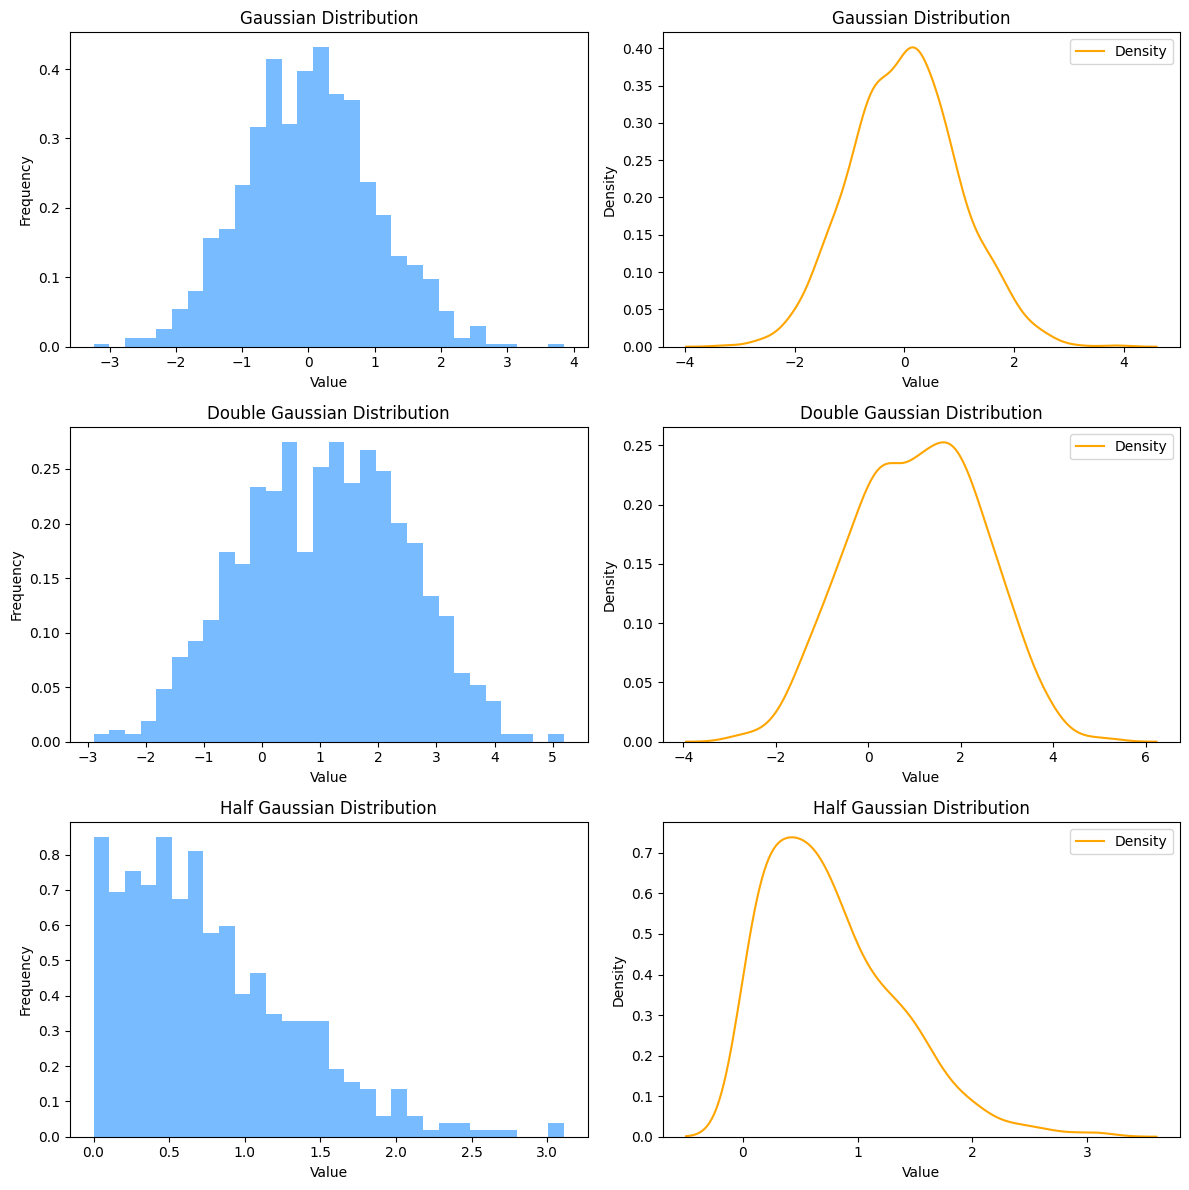

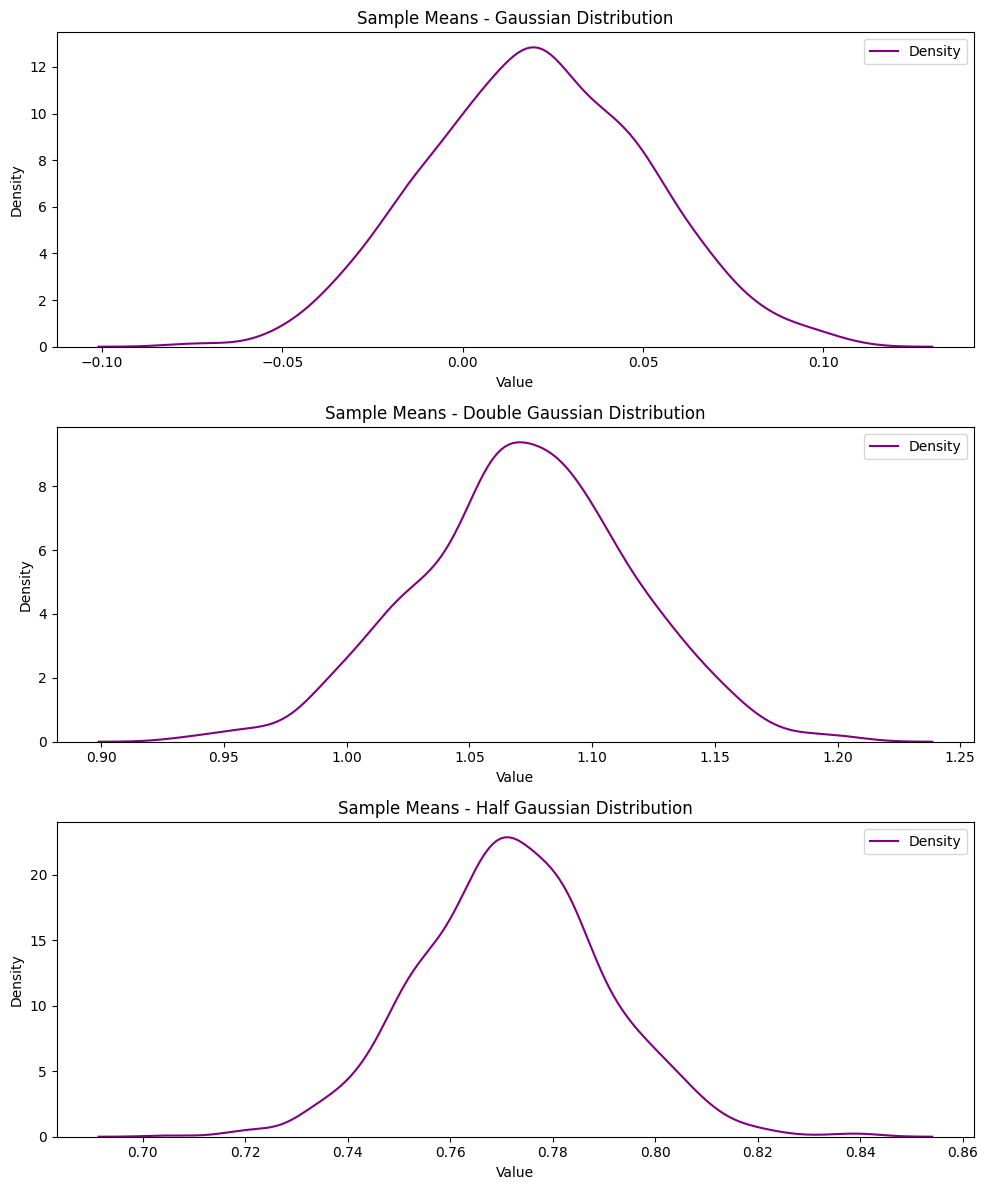

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a random seed for reproducibility
np.random.seed(42)

# Mean for all distributions
mean = 0

# Sample size for each distribution
sample_size = 1000

# Generate the Gaussian distribution
gaussian_distribution = np.random.normal(loc=mean, scale=1, size=sample_size)

# Generate the double Gaussian distribution
double_gaussian_distribution = np.concatenate((np.random.normal(loc=mean, scale=1, size=sample_size//2),
                                              np.random.normal(loc=mean+2, scale=1, size=sample_size//2)))

# Generate the half Gaussian distribution
half_gaussian_distribution = np.abs(np.random.normal(loc=mean, scale=1, size=sample_size//2))

# Plotting the frequency histogram and density curve for each distribution
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
distributions = [gaussian_distribution, double_gaussian_distribution, half_gaussian_distribution]
distribution_labels = ['Gaussian', 'Double Gaussian', 'Half Gaussian']

for i, (distribution, label) in enumerate(zip(distributions, distribution_labels)):
    # Histogram
    axes[i, 0].hist(distribution, bins=30, density=True, alpha=0.6, color='dodgerblue')
    axes[i, 0].set_title(f'{label} Distribution')
    axes[i, 0].set_xlabel('Value')
    axes[i, 0].set_ylabel('Frequency')

    # Density curve
    sns.kdeplot(distribution, ax=axes[i, 1], color='orange', label='Density')
    axes[i, 1].set_title(f'{label} Distribution')
    axes[i, 1].set_xlabel('Value')
    axes[i, 1].set_ylabel('Density')
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

# Generate and analyze sample means from each distribution
num_samples = 1000
sample_means = []
sample_means_labels = ['Gaussian', 'Double Gaussian', 'Half Gaussian']

for distribution, label in zip(distributions, distribution_labels):
    means = []
    for _ in range(num_samples):
        sample = np.random.choice(distribution, size=sample_size, replace=True)
        means.append(sample.mean())
    sample_means.append(means)

# Plotting the density curve for sample means
fig, axes = plt.subplots(3, figsize=(10, 12))

for i, (means, label) in enumerate(zip(sample_means, sample_means_labels)):
    # Density curve
    sns.kdeplot(means, ax=axes[i], color='purple', label='Density')
    axes[i].set_title(f'Sample Means - {label} Distribution')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Density')
    axes[i].legend()

plt.tight_layout()
plt.show()


Convergence de  la t- distribution vers la z-distribution lorsque n tend vers l'infini

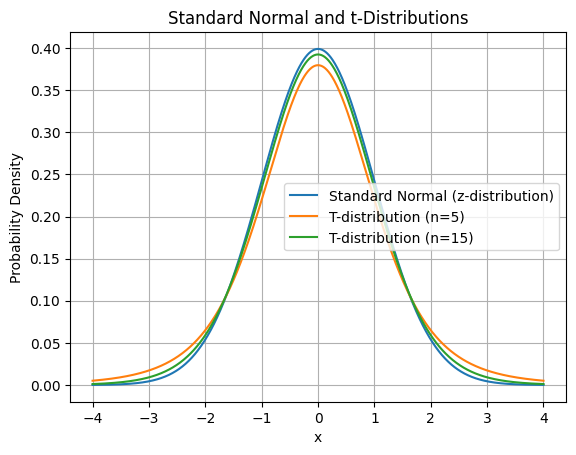

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t

# Define the range for x-axis
x = np.linspace(-4, 4, 1000)

# Standard normal distribution (z-distribution)
z_distribution = norm.pdf(x, 0, 1)

# T-distribution with different degrees of freedom (n values)
n_values = [5, 15]  # Change this list to your desired n values
t_distributions = [t.pdf(x, df) for df in n_values]

# Plot the distributions
plt.plot(x, z_distribution, label='Standard Normal (z-distribution)')
plt.plot(x, t_distributions[0], label='T-distribution (n={})'.format(n_values[0]))
plt.plot(x, t_distributions[1], label='T-distribution (n={})'.format(n_values[1]))

# Add labels and legend
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title('Standard Normal and t-Distributions')
plt.legend()

# Show the plot
plt.grid(True)
plt.show()


Biais de l'estimateur empririque

Estimateur biaisé de la variance moyen : 4.822175470615387
Estimateur non biaisé de la variance moyen : 4.988457383395229


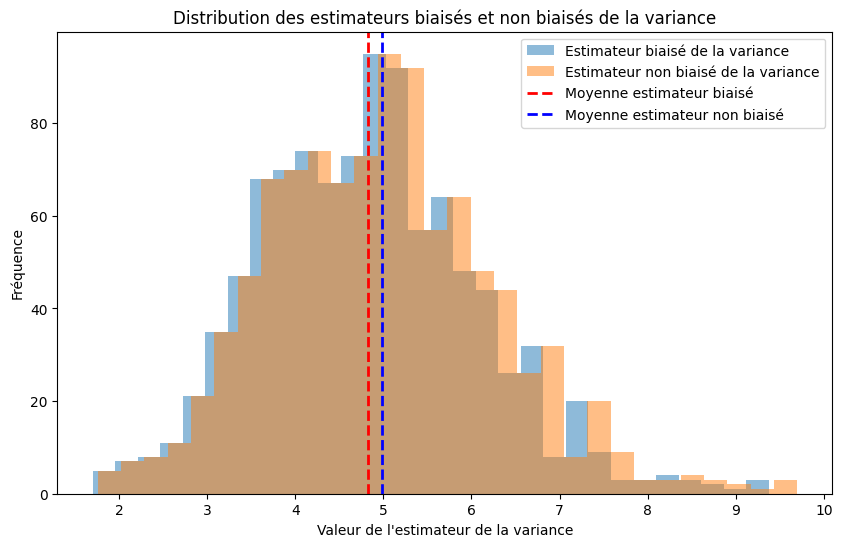

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Paramètres
np.random.seed(42)
population_mean = 10
population_variance = 5
sample_size = 30
num_simulations = 1000

# Fonction pour calculer l'estimateur biaisé et non biaisé de la variance
def calculate_biased_and_unbiased_var(data):
    n = len(data)
    mean = np.mean(data)
    biased_var = np.sum((data - mean)**2) / n
    unbiased_var = np.sum((data - mean)**2) / (n - 1)
    return biased_var, unbiased_var

# Simulation
biased_variances = []
unbiased_variances = []

for _ in range(num_simulations):
    # Générer un échantillon aléatoire de la population
    sample = np.random.normal(loc=population_mean, scale=np.sqrt(population_variance), size=sample_size)

    # Calculer les estimateurs biaisé et non biaisé de la variance
    biased_var, unbiased_var = calculate_biased_and_unbiased_var(sample)

    # Stocker les résultats
    biased_variances.append(biased_var)
    unbiased_variances.append(unbiased_var)

# Afficher les résultats moyens
mean_biased_var = np.mean(biased_variances)
mean_unbiased_var = np.mean(unbiased_variances)

print(f"Estimateur biaisé de la variance moyen : {mean_biased_var}")
print(f"Estimateur non biaisé de la variance moyen : {mean_unbiased_var}")


# Afficher l'histogramme des estimateurs
plt.figure(figsize=(10, 6))

plt.hist(biased_variances, bins=30, alpha=0.5, label='Estimateur biaisé de la variance')
plt.hist(unbiased_variances, bins=30, alpha=0.5, label='Estimateur non biaisé de la variance')

plt.axvline(x=mean_biased_var, color='red', linestyle='dashed', linewidth=2, label='Moyenne estimateur biaisé')
plt.axvline(x=mean_unbiased_var, color='blue', linestyle='dashed', linewidth=2, label='Moyenne estimateur non biaisé')

plt.xlabel('Valeur de l\'estimateur de la variance')
plt.ylabel('Fréquence')
plt.legend()
plt.title('Distribution des estimateurs biaisés et non biaisés de la variance')

plt.show()
